**Noah's Story: The Battle Nobody Could See**

Meet Noah, a young person who appears to live a normal life but struggles with unwanted thoughts, anxiety, and recurring doubts that are difficult to silence.

What others may see as unnecessary checking or repetitive behavior can be part of a deeper struggle. This is one way obsessive compulsive disorder (OCD) can affect a person's daily life.

Noah's story reminds us that we cannot always understand someone's struggles from what we see on the outside.

In this project, we will explore OCD through data, using statistics and machine learning to uncover patterns in reported symptoms and reflect on what these findings can teach us about human experiences.

Data Source : https://github.com/Raghu99484/ocd-patient-dataset

In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy import stats

# Machine learning tools
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Display settings
pd.set_option("display.max_columns", None)

# Visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


**Understanding the dataset**

This dataset contains 1,500 records describing individuals with OCD, including their demographic backgrounds, symptom duration, obsession and compulsion types, symptom severity scores, previous diagnoses, and treatment information.

What the Data Reveals

The records cover individuals aged 18 to 75, with an average age of approximately 47 years. The average reported symptom duration is about 10 years. Depression is recorded in 772 cases, while anxiety is recorded in 751 cases. The average Y-BOCS scores are approximately 20 for both obsessions and compulsions.

These figures offer a starting point for investigating patterns in OCD symptoms and their relationships with other recorded characteristics. However, they do not establish cause and effect, and missing information must be considered before drawing conclusions.

In this project, i will use data analysis and visualization to explore what the records reveal, test relationships between variables, and distinguish evidence based findings from assumptions about people living with OCD.

In [7]:
#importing the dataset

import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv('/Users/macbook/Desktop/ocd_patient_dataset.csv')

# Display the first five rows
df.head()


,Patient ID,Age,Gender,Ethnicity,Marital Status,Education Level,OCD Diagnosis Date,Duration of Symptoms (months),Previous Diagnoses,Family History of OCD,Obsession Type,Compulsion Type,Y-BOCS Score (Obsessions),Y-BOCS Score (Compulsions),Depression Diagnosis,Anxiety Diagnosis,Medications
0,1018,32,Female,African,Single,Some College,2016-07-15,203,MDD,No,Harm-related,Checking,17,10,Yes,Yes,SNRI
1,2406,69,Male,African,Divorced,Some College,2017-04-28,180,NaN,Yes,Harm-related,Washing,21,25,Yes,Yes,SSRI
2,1188,57,Male,Hispanic,Divorced,College Degree,2018-02-02,173,MDD,No,Contamination,Checking,3,4,No,No,Benzodiazepine
3,6200,27,Female,Hispanic,Married,College Degree,2014-08-25,126,PTSD,Yes,Symmetry,Washing,14,28,Yes,Yes,SSRI
4,5824,56,Female,Hispanic,Married,High School,2022-02-20,168,PTSD,Yes,Hoarding,Ordering,39,18,No,No,NaN


### Dataset Variables and Their Purpose

| Variable | Type | What it reveals |
|---|---|---|
| Patient ID | ID | Identifies records |
| Age | Numeric | Age patterns |
| Gender | Category | Gender differences |
| Ethnicity | Category | Ethnic group patterns |
| Marital Status | Category | Marital group patterns |
| Education Level | Category | Education patterns |
| OCD Diagnosis Date | Date | Diagnosis timing |
| Duration of Symptoms | Numeric | Symptom duration |
| Previous Diagnoses | Category | Prior diagnoses |
| Family History of OCD | Category | Family history |
| Obsession Type | Category | Obsession patterns |
| Compulsion Type | Category | Compulsion patterns |
| Y-BOCS Obsession Score | Numeric | Obsession severity |
| Y-BOCS Compulsion Score | Numeric | Compulsion severity |
| Depression Diagnosis | Category | Depression occurrence |
| Anxiety Diagnosis | Category | Anxiety occurrence |
| Medications | Category | Recorded treatments |


In [12]:
#Data inspection and cleaning 

print("Dataset shape:", df.shape)
print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Unique patient IDs:", df["Patient ID"].nunique())
print("Repeated patient IDs:", df["Patient ID"].duplicated().sum())

Dataset shape: (1500, 17)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 17 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Patient ID                     1500 non-null   int64 
 1   Age                            1500 non-null   int64 
 2   Gender                         1500 non-null   object
 3   Ethnicity                      1500 non-null   object
 4   Marital Status                 1500 non-null   object
 5   Education Level                1500 non-null   object
 6   OCD Diagnosis Date             1500 non-null   object
 7   Duration of Symptoms (months)  1500 non-null   int64 
 8   Previous Diagnoses             1252 non-null   object
 9   Family History of OCD          1500 non-null   object
 10  Obsession Type                 1500 non-null   object
 11  Compulsion Type                1500 non-null   object
 12  Y-BOCS Score (O

## What the Results Reveal

| Check | Result | Interpretation |
|---|---:|---|
| Missing previous diagnoses | 248 | Some medical history information is unavailable. |
| Missing medications | 386 | Treatment information is incomplete. |
| Duplicate rows | 0 | No completely identical rows were found. |
| Total records | 1,500 | The dataset contains 1,500 rows. |
| Unique patient IDs | 1,393 | There are fewer unique IDs than records. |
| Repeated patient IDs | 107 | There are 107 records beyond the unique ID count. |


### Investigating Repeated Patient IDs: Are We Counting People or Records?

Imagine a clinical research team reviewing patient records to understand the experiences of people living with OCD. Before analyzing symptom severity or comparing patient characteristics, the team must establish how many individuals are represented in the data.

The dataset contains 1,500 records but only 1,393 unique patient IDs. This raises an important question: why do some identifiers appear more than once?

In a real clinical setting, repeated IDs might represent follow up visits, multiple assessments, or errors introduced during data collection. Each possibility has different implications for the analysis. Counting the same individual multiple times as though they were different people could distort summary statistics and lead to misleading conclusions.

However, we cannot assume that the repeated IDs represent follow up visits or errors without examining the records. Next step is to identify the repeated IDs and inspect their associated information. This will help us understand the structure of the dataset before proceeding with further analysis.


In [20]:

# Count how often each patient ID appears
id_counts = df["Patient ID"].value_counts()

# Identify IDs appearing more than once
repeated_ids = id_counts[id_counts > 1]

print("Distinct IDs that appear more than once:", len(repeated_ids))
print("Extra occurrences beyond the first:", id_counts.sum() - df["Patient ID"].nunique())

print("\nMost frequently repeated IDs:")
print(repeated_ids.head(10))

# Inspect records associated with the first repeated ID
if not repeated_ids.empty:
    example_id = repeated_ids.index[0]

    print(f"\nRecords for Patient ID: {example_id}")
    display(
        df[df["Patient ID"] == example_id]
        .sort_values("OCD Diagnosis Date")
    )


Distinct IDs that appear more than once: 99
Extra occurrences beyond the first: 107

Most frequently repeated IDs:
Patient ID
4940    4
4315    3
1885    3
4884    3
6195    3
9431    3
8880    3
3273    2
5667    2
8335    2
Name: count, dtype: int64

Records for Patient ID: 4940


,Patient ID,Age,Gender,Ethnicity,Marital Status,Education Level,OCD Diagnosis Date,Duration of Symptoms (months),Previous Diagnoses,Family History of OCD,Obsession Type,Compulsion Type,Y-BOCS Score (Obsessions),Y-BOCS Score (Compulsions),Depression Diagnosis,Anxiety Diagnosis,Medications
235,4940,66,Female,Hispanic,Single,Some College,2015-04-11,94,NaN,Yes,Contamination,Washing,9,10,No,Yes,SNRI
611,4940,25,Female,Caucasian,Divorced,Some College,2016-05-09,10,MDD,No,Hoarding,Counting,13,37,Yes,Yes,Benzodiazepine
1392,4940,59,Female,Asian,Divorced,Some College,2018-06-22,98,PTSD,Yes,Harm-related,Praying,16,39,Yes,No,Benzodiazepine
1099,4940,35,Female,Hispanic,Single,Some College,2021-07-09,104,GAD,Yes,Hoarding,Counting,9,5,No,Yes,SNRI


In [21]:
id_counts = df["Patient ID"].value_counts()
repeated_ids = id_counts[id_counts > 1]

len(repeated_ids)

99

In [22]:
repeated_ids.sort_values(ascending=False)

Patient ID
4940    4
4315    3
1885    3
4884    3
6195    3
       ..
7092    2
1018    2
3516    2
5759    2
6251    2
Name: count, Length: 99, dtype: int64

In [23]:
df[df["Patient ID"] == 4940]

,Patient ID,Age,Gender,Ethnicity,Marital Status,Education Level,OCD Diagnosis Date,Duration of Symptoms (months),Previous Diagnoses,Family History of OCD,Obsession Type,Compulsion Type,Y-BOCS Score (Obsessions),Y-BOCS Score (Compulsions),Depression Diagnosis,Anxiety Diagnosis,Medications
235,4940,66,Female,Hispanic,Single,Some College,2015-04-11,94,NaN,Yes,Contamination,Washing,9,10,No,Yes,SNRI
611,4940,25,Female,Caucasian,Divorced,Some College,2016-05-09,10,MDD,No,Hoarding,Counting,13,37,Yes,Yes,Benzodiazepine
1099,4940,35,Female,Hispanic,Single,Some College,2021-07-09,104,GAD,Yes,Hoarding,Counting,9,5,No,Yes,SNRI
1392,4940,59,Female,Asian,Divorced,Some College,2018-06-22,98,PTSD,Yes,Harm-related,Praying,16,39,Yes,No,Benzodiazepine


**Descriptive Statisitics**

In [32]:
df.describe()

,Patient ID,Age,Duration of Symptoms (months),Y-BOCS Score (Obsessions),Y-BOCS Score (Compulsions)
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.00000
mean,5541.254000,46.781333,121.745333,20.048000,19.62600
std,2562.389469,16.830321,67.404610,11.823884,11.78287
min,1017.000000,18.000000,6.000000,0.000000,0.00000
25%,3338.000000,32.000000,64.000000,10.000000,9.00000
50%,5539.500000,47.000000,121.000000,20.000000,20.00000
75%,7745.500000,61.000000,178.000000,31.000000,29.00000
max,9995.000000,75.000000,240.000000,40.000000,40.00000


In [34]:
df[[
    "Age",
    "Duration of Symptoms (months)",
    "Y-BOCS Score (Obsessions)",
    "Y-BOCS Score (Compulsions)"
]].describe().round(2)

,Age,Duration of Symptoms (months),Y-BOCS Score (Obsessions),Y-BOCS Score (Compulsions)
count,1500.00,1500.00,1500.00,1500.00
mean,46.78,121.75,20.05,19.63
std,16.83,67.40,11.82,11.78
min,18.00,6.00,0.00,0.00
25%,32.00,64.00,10.00,9.00
50%,47.00,121.00,20.00,20.00
75%,61.00,178.00,31.00,29.00
max,75.00,240.00,40.00,40.00


### Summary of Descriptive Statistics

The descriptive statistics summarize 1,500 records in the OCD dataset. The average age is 46.78 years, with a median of 47 and an age range of 18 to 75 years. The duration of symptoms averages 121.75 months (approximately 10.1 years), ranging from 6 to 240 months.

The mean Y-BOCS obsession score is 20.05, while the mean compulsion score is 19.63. Both have a median of approximately 20 and range from 0 to 40. The relatively similar averages suggest that the two score distributions have comparable central values in this dataset.

Overall, these statistics provide an initial picture of the records, including patient ages, symptom duration, and Y-BOCS scores. Further analysis and visualizations can help us better understand the distributions and identify patterns.

**Visualization**

Age Distribution: Concentration of OCD Records Across Age Groups :visualize the age distribution of patients in our dataset and identify which age groups have the highest concentration of records. This will help us understand how patients are represented across different ages, without assuming that these patterns reflect OCD prevalence in the general population.

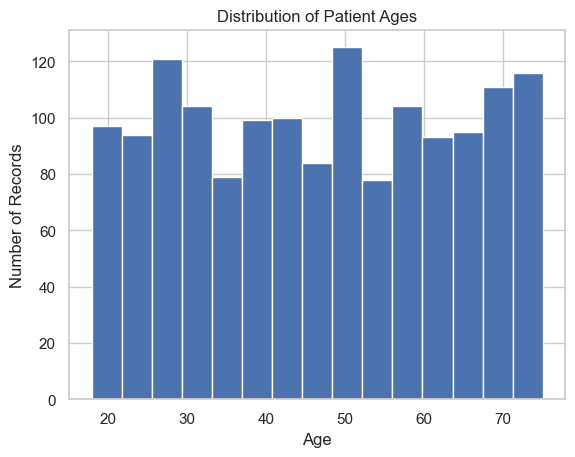

In [35]:
import matplotlib.pyplot as plt

df["Age"].hist(bins=15)
plt.title("Distribution of Patient Ages")
plt.xlabel("Age")
plt.ylabel("Number of Records")
plt.show()

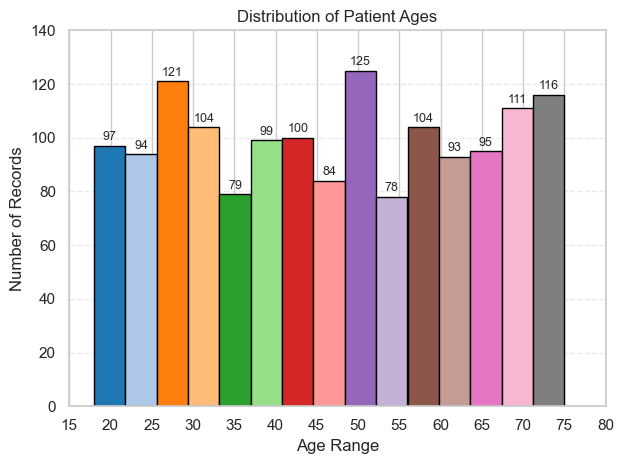

In [36]:

import matplotlib.pyplot as plt

ages = df["Age"]

# Create the histogram
counts, bins, bars = plt.hist(
    ages,
    bins=15,
    edgecolor="black"
)

# Give every bin a different color
colors = plt.cm.tab20(range(len(bars)))
for bar, color in zip(bars, colors):
    bar.set_facecolor(color)

# Add the count above each bar
for count, bar in zip(counts, bars):
    if count > 0:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            count + 2,
            int(count),
            ha="center",
            fontsize=9
        )

plt.title("Distribution of Patient Ages")
plt.xlabel("Age Range")
plt.ylabel("Number of Records")

# Show age ticks
plt.xticks(range(15, 81, 5))
plt.yticks(range(0, int(max(counts)) + 21, 20))

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


The histogram shows the highest concentration of records around the late forties to early fifties. Several factors could potentially contribute to this pattern, including differences in when individuals receive an OCD diagnosis and the demographic composition of the dataset. 

What might explain this pattern?
- Accumulated experiences: By midlife, people may have experienced years of stress and life changes that could influence their mental health.
- Recognition and diagnosis: Some people may receive an OCD diagnosis later in life, even if their symptoms began much earlier.
- Dataset composition: The peak could simply reflect how this particular dataset was collected or constructed.

However, the visualization does not establish why this age interval contains the most records, nor does it demonstrate that OCD is most prevalent in this age group. Further information about symptom onset, diagnosis, and the dataset's sampling method would be needed to investigate these possibilities.



**identify which obsession types occur most frequently among the records in our OCD dataset.**

In [40]:
df["Obsession Type"].value_counts()

Obsession Type
Harm-related     333
Contamination    306
Religious        303
Symmetry         280
Hoarding         278
Name: count, dtype: int64

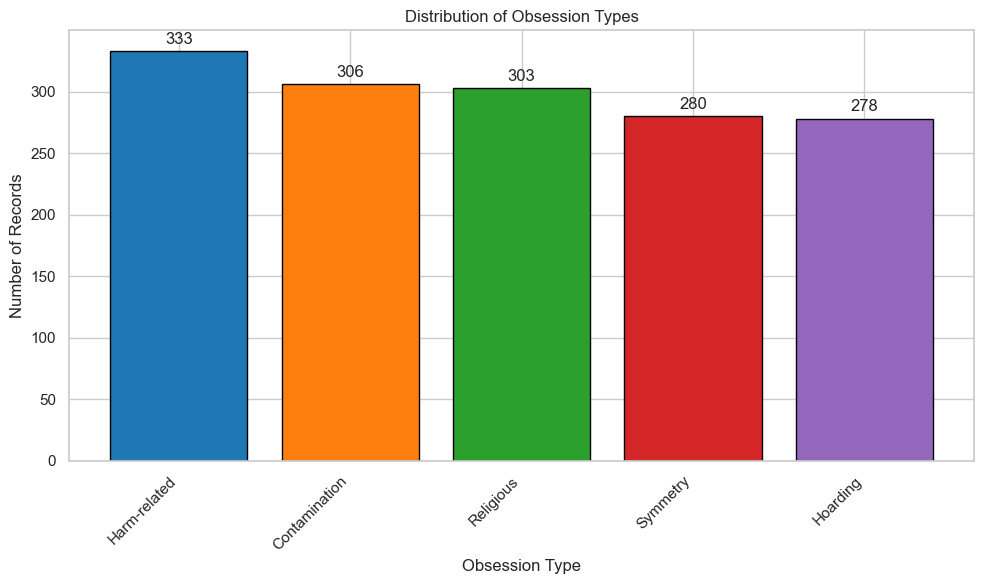

In [41]:
import matplotlib.pyplot as plt

counts = df["Obsession Type"].value_counts()

plt.figure(figsize=(10, 6))
bars = plt.bar(
    counts.index,
    counts.values,
    color=plt.cm.tab10.colors[:len(counts)],
    edgecolor="black"
)

plt.bar_label(bars, padding=3)
plt.title("Distribution of Obsession Types")
plt.xlabel("Obsession Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Why Might Harm-Related Obsessions Be So Prominent?

Imagine Noah walking into a room and seeing a dead body on the floor. Although he has no evidence that he caused the death, a frightening thought enters his mind: *What if I was the killer?*

The thought unsettles him. He begins replaying what happened, searching his memory for clues and questioning whether he could have done something terrible without realizing it. The more he tries to prove his innocence to himself, the more the doubt returns.

For someone experiencing harm-related OCD, the fear of causing harm can become a distressing cycle of unwanted thoughts, doubt, and repeated attempts to find certainty. The thought itself does not mean Noah is dangerous or wants to hurt anyone.

Perhaps this helps us understand why harm-related obsessions deserve attention in our analysis. However, while harm appears most frequently in our dataset, Noah's story illustrates one possible experience; it does not explain why this category ranks highest in the data.

**investigate how obsession types vary across different age groups**

in our dataset. By comparing age groups with obsession types, we can identify patterns in how patients are represented and explore whether certain obsession types appear more frequently within particular age groups.

In [42]:
#create age group and compare with obsession type
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create age groups
bins = [18, 25, 35, 45, 55, 65, 76]
labels = ['18–24', '25–34', '35–44', '45–54', '55–64', '65–75']

df['Age Group'] = pd.cut(
    df['Age'],
    bins=bins,
    labels=labels,
    right=False
)

# Compare age groups with obsession types
obsession_table = pd.crosstab(
    df['Age Group'],
    df['Obsession Type']
)

display(obsession_table)


Obsession Type,Contamination,Harm-related,Hoarding,Religious,Symmetry
Age Group,,,,,
18–24,31,33,28,29,43
25–34,57,51,46,66,53
35–44,54,58,59,43,43
45–54,53,71,50,44,41
55–64,53,54,46,52,47
65–75,58,66,49,69,53


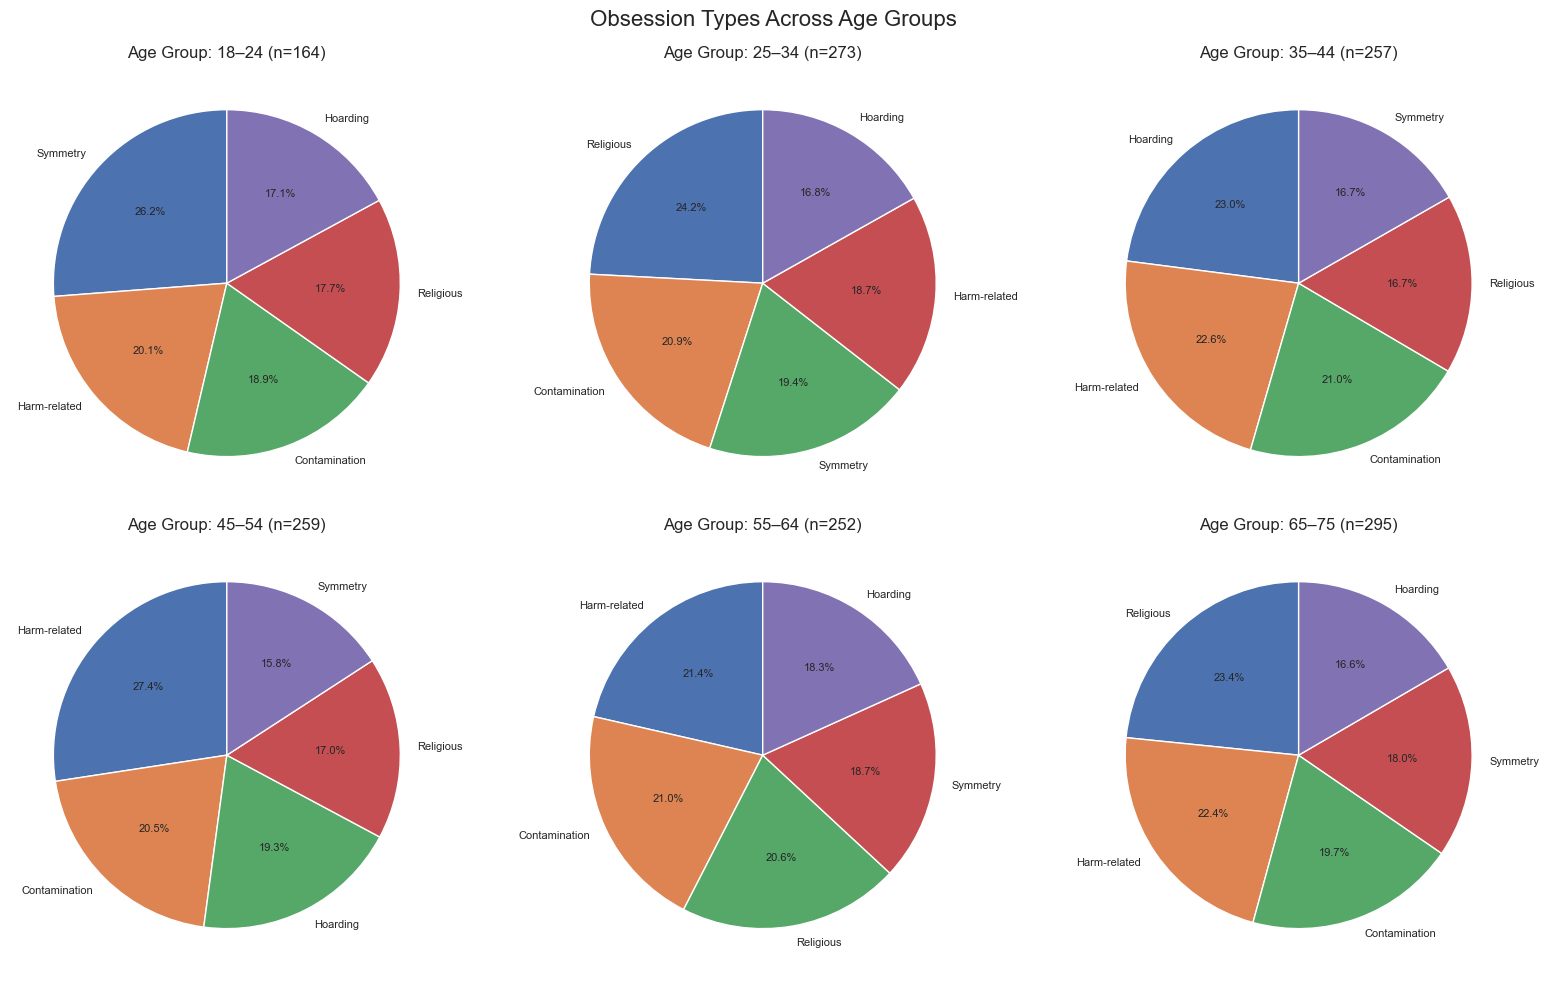

In [44]:


import matplotlib.pyplot as plt

# Create age groups if not already created
bins = [18, 25, 35, 45, 55, 65, 76]
labels = ['18–24', '25–34', '35–44', '45–54', '55–64', '65–75']

df['Age Group'] = pd.cut(
    df['Age'],
    bins=bins,
    labels=labels,
    right=False
)

# Create a separate pie chart for each age group
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, age_group in zip(axes, labels):
    group_data = df[df['Age Group'] == age_group]
    obsession_counts = group_data['Obsession Type'].value_counts()

    ax.pie(
        obsession_counts,
        labels=obsession_counts.index,
        autopct='%1.1f%%',
        startangle=90,
        textprops={'fontsize': 8}
    )

    ax.set_title(f'Age Group: {age_group} (n={len(group_data)})')

plt.suptitle('Obsession Types Across Age Groups', fontsize=16)
plt.tight_layout()
plt.show()


**A little observation about the 25–34 age group 😂**

Ah, 25–34! That stage of life when a man starts taking life a little more seriously. Career, purpose, relationships, and of course… God! 🙏🏽 Suddenly, he wants to understand his calling, strengthen his faith, and get his spiritual life in order.

But what happens when the desire to get everything right becomes a little *too* intense? For someone experiencing religious OCD, questions about faith, sin, and whether they have done something wrong can become a distressing cycle of doubt and reassurance-seeking.

**Could this be why religious obsessions appear in this age group?** 👀 Let's look at the data!

*Of course, this is just our playful hypothesis. The charts can show us what appears in our dataset, but they cannot tell us why a pattern exists or prove that people aged 25–34 experience more religious OCD than other age groups.*

Na joke o 😂

### Objective: OCD Records by Gender

To examine the distribution of OCD patient records by gender and identify which gender is represented most frequently in our dataset. This will help us understand the gender composition of the data, without assuming that a higher number of records means a higher OCD prevalence in the general population.

In [45]:

# Count records by gender
gender_counts = df['Gender'].value_counts()

display(gender_counts)

# Calculate percentages
gender_percentages = df['Gender'].value_counts(normalize=True) * 100

display(gender_percentages.round(2))


Gender
Male      753
Female    747
Name: count, dtype: int64

Gender
Male      50.2
Female    49.8
Name: proportion, dtype: float64

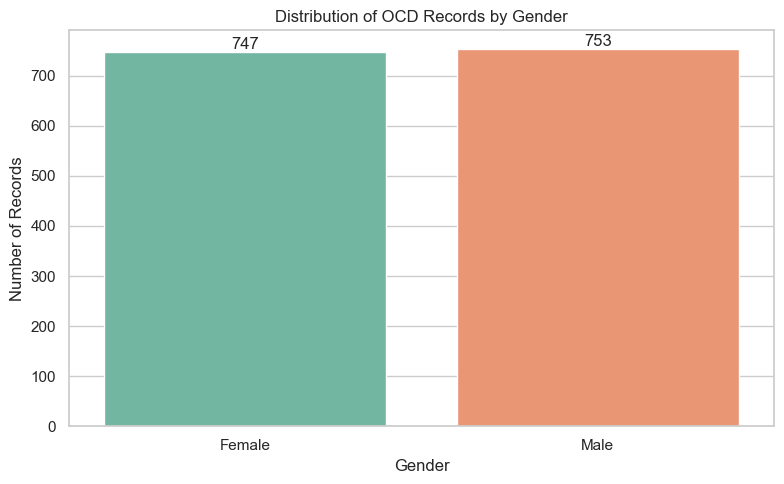

In [46]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='Gender',
    hue='Gender',
    palette='Set2',
    legend=False
)

# Add counts above the bars
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f'{int(height)}',
        (bar.get_x() + bar.get_width() / 2, height),
        ha='center',
        va='bottom'
    )

plt.title('Distribution of OCD Records by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Records')
plt.tight_layout()
plt.show()


### Men, Mental Health, and the Art of Bottling It Up 

Honestly, I wouldn't be surprised if men had a lot to say about this one.

From childhood, some boys are practically enrolled in the *School of Emotional Suppression*. The curriculum? “Suck it up.” “Don't cry.” “Be a man!” Graduate with honors, and you earn a lifetime membership in the *Bottle It Up Society*. 😂

Imagine a man telling his friends, “Bro, I'm struggling with intrusive thoughts.”

“WHAT? As a man? You have OCD? Guy, just man up!” 😭

So, he laughs it off, changes the subject, and goes home to fight a thousand battles in his mind that nobody knows about.

But here's the reality: **being a man doesn't make someone immune to OCD, anxiety, or emotional distress.** Some men may struggle silently because they feel pressured to appear strong, even when their minds won't give them a moment's peace.

Sometimes, the strongest-looking person in the room is fighting a battle nobody can see.


### Objective: Exploring OCD Patterns Across Demographics

To explore patterns in the dataset by examining the relationship between age group, gender, and obsession type. This analysis will help identify which combinations of demographic groups and obsession types have the highest number of records and whether any interesting patterns emerge.

The goal is to explore the data rather than assume that these patterns represent OCD prevalence in the wider population.

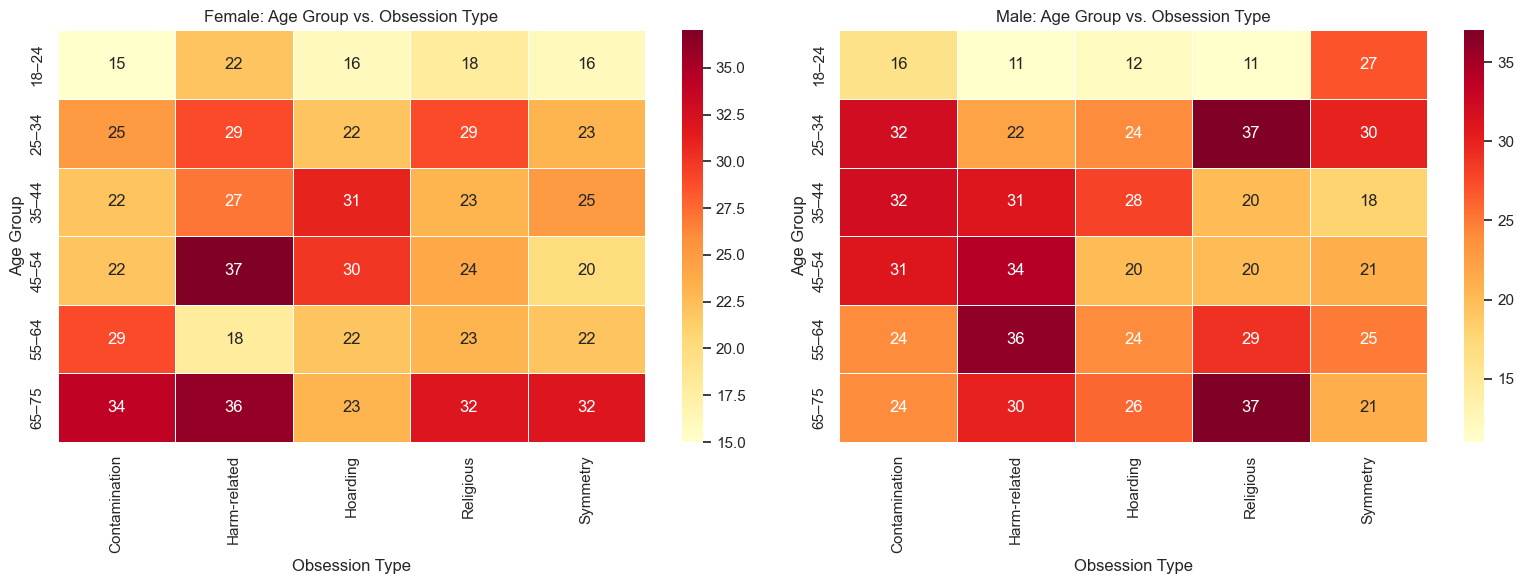

In [48]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create age groups if you have not already done so
bins = [18, 25, 35, 45, 55, 65, 76]
labels = ['18–24', '25–34', '35–44', '45–54', '55–64', '65–75']

df['Age Group'] = pd.cut(
    df['Age'],
    bins=bins,
    labels=labels,
    right=False
)

genders = df['Gender'].dropna().unique()

fig, axes = plt.subplots(
    1, len(genders),
    figsize=(8 * len(genders), 6),
    squeeze=False
)

for ax, gender in zip(axes.flatten(), genders):
    subset = df[df['Gender'] == gender]

    table = pd.crosstab(
        subset['Age Group'],
        subset['Obsession Type']
    ).reindex(labels, fill_value=0)

    sns.heatmap(
        table,
        annot=True,
        fmt='d',
        cmap='YlOrRd',
        linewidths=0.5,
        ax=ax
    )

    ax.set_title(f'{gender}: Age Group vs. Obsession Type')
    ax.set_xlabel('Obsession Type')
    ax.set_ylabel('Age Group')

plt.tight_layout()
plt.show()


## What Does the Heatmap Reveal?

The heatmap reveals that obsession types are not evenly distributed across age groups and genders in our dataset. Some combinations stand out more than others.

Among females, harm-related obsessions show a high count in the 45–54 age group. Among males, religious obsessions stand out in both the 25–34 and 65–75 age groups.

### Quick Question: Why Do Women Aged 45–54 Show a High Count of Harm-Related Obsessions?

My guess? **Hormonal changes during perimenopause and menopause could be one possible explanation.**

Women between the ages of 45 and 54 may be experiencing perimenopause or menopause. During this transition, fluctuations in estrogen and progesterone can influence mood, sleep, and anxiety. These changes could potentially affect how some women experience or cope with OCD symptoms.

Serotonin, a chemical messenger in the brain, plays a role in mood regulation and other processes relevant to OCD. However, the relationship between hormonal changes, serotonin, and OCD symptoms is complex, and we cannot conclude that hormonal fluctuations explain the pattern in our heatmap.

Here is something worth remembering: **almost everyone experiences intrusive thoughts from time to time.** A person might suddenly imagine something frightening or have an unwanted thought that goes against their values. Having such thoughts does not mean they want them to happen.

For someone with OCD, however, certain intrusive thoughts can become distressing and persistent. They may feel threatening, create intense uncertainty, and trigger repeated attempts to seek reassurance, check, or mentally neutralize the thought.

So, could hormonal changes contribute to the higher count we see among women aged 45–54? It is a possibility worth investigating, but it remains a hypothesis, not a conclusion.



### Objective: Understanding OCD Symptom Severity

To examine the distribution of obsession and compulsion scores using the Y-BOCS measures in our dataset. We will explore the range of recorded scores, identify common score patterns, and investigate whether obsession and compulsion scores are related.

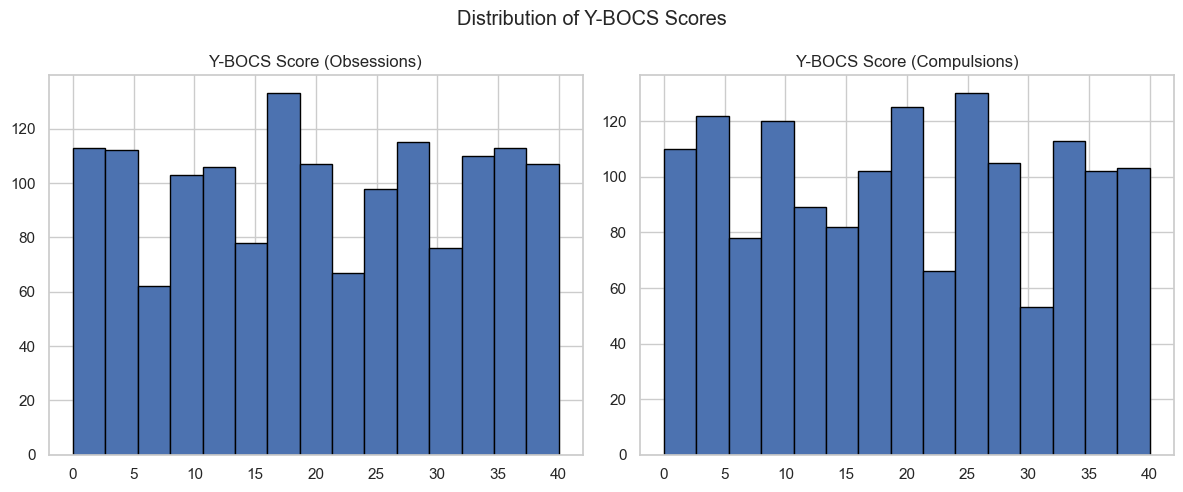

,Y-BOCS Score (Obsessions),Y-BOCS Score (Compulsions)
count,1500.000000,1500.00000
mean,20.048000,19.62600
std,11.823884,11.78287
min,0.000000,0.00000
25%,10.000000,9.00000
50%,20.000000,20.00000
75%,31.000000,29.00000
max,40.000000,40.00000


In [49]:

import matplotlib.pyplot as plt
import seaborn as sns

score_columns = [
    'Y-BOCS Score (Obsessions)',
    'Y-BOCS Score (Compulsions)'
]

df[score_columns].hist(
    bins=15,
    figsize=(12, 5),
    edgecolor='black'
)

plt.suptitle('Distribution of Y-BOCS Scores')
plt.tight_layout()
plt.show()

display(df[score_columns].describe())


### Interpreting the Distribution of Y-BOCS Scores

The histograms show that both obsession and compulsion scores are distributed across a broad range of values in our dataset. Rather than concentrating within a single score interval, the records are spread across multiple ranges, with some intervals appearing more frequently than others.

For obsession scores, one of the highest concentrations appears around 16–18, while compulsion scores show a prominent concentration around 24–27. This suggests that the two score distributions have different patterns, although the histograms alone cannot establish whether the difference is statistically meaningful.

### Objective: Symptom Duration and OCD Scores

To investigate whether the duration of OCD symptoms is associated with recorded obsession and compulsion scores. This analysis will help us explore whether patients with longer symptom durations tend to have higher symptom scores in our dataset.

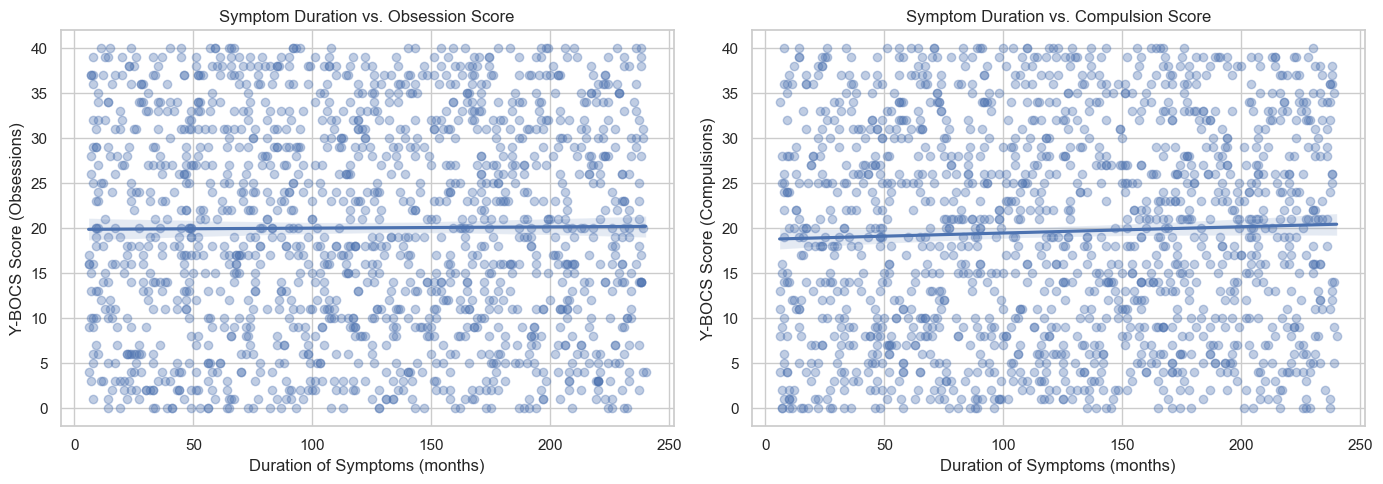

In [51]:

import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(
    data=df,
    x='Duration of Symptoms (months)',
    y='Y-BOCS Score (Obsessions)',
    scatter_kws={'alpha': 0.35},
    ax=axes[0]
)
axes[0].set_title('Symptom Duration vs. Obsession Score')

sns.regplot(
    data=df,
    x='Duration of Symptoms (months)',
    y='Y-BOCS Score (Compulsions)',
    scatter_kws={'alpha': 0.35},
    ax=axes[1]
)
axes[1].set_title('Symptom Duration vs. Compulsion Score')

plt.tight_layout()
plt.show()



The scatter plots reveal no strong visual relationship between the duration of OCD symptoms and recorded symptom scores.

For obsession scores, the trend line is almost flat, suggesting that scores do not consistently increase as symptom duration increases. Compulsion scores show a slight upward trend, although the data points remain widely scattered.

Interestingly, records with both short and long symptom durations contain a broad range of scores. This suggests that symptom duration alone may not be sufficient to explain the differences in recorded obsession and compulsion scores.

However, these are visual observations. We need to calculate the correlation coefficients before drawing stronger conclusions, and even then, correlation would not establish causation.

In [52]:

duration_col = 'Duration of Symptoms (months)'
obsession_col = 'Y-BOCS Score (Obsessions)'
compulsion_col = 'Y-BOCS Score (Compulsions)'

print(
    "Duration vs. obsession score:",
    df[duration_col].corr(df[obsession_col]).round(3)
)

print(
    "Duration vs. compulsion score:",
    df[duration_col].corr(df[compulsion_col]).round(3)
)


Duration vs. obsession score: 0.008
Duration vs. compulsion score: 0.04


### Objective: Depression, Anxiety, and OCD Symptom Scores

To explore the relationship between recorded depression and anxiety diagnoses and OCD symptom scores in our dataset. We will compare obsession and compulsion scores between patients with and without each recorded diagnosis to identify any noticeable differences.

This analysis explores associations within the dataset and does not establish that depression or anxiety causes more severe OCD symptoms.

In [54]:

print("Depression Diagnosis:")
print(df['Depression Diagnosis'].value_counts(dropna=False))

print("\nAnxiety Diagnosis:")
print(df['Anxiety Diagnosis'].value_counts(dropna=False))


Depression Diagnosis:
Depression Diagnosis
Yes    772
No     728
Name: count, dtype: int64

Anxiety Diagnosis:
Anxiety Diagnosis
Yes    751
No     749
Name: count, dtype: int64


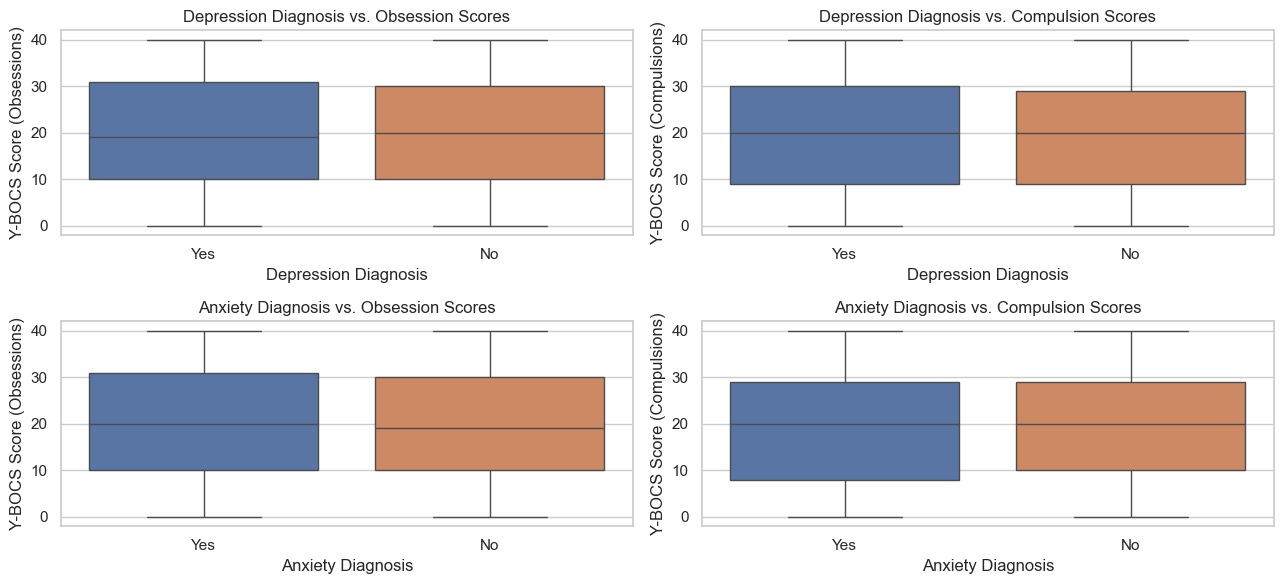

In [60]:
#Compare the score distribution

import matplotlib.pyplot as plt
import seaborn as sns

score_columns = [
    'Y-BOCS Score (Obsessions)',
    'Y-BOCS Score (Compulsions)'
]

fig, axes = plt.subplots(2, 2, figsize=(13, 6))

sns.boxplot(
    data=df,
    x='Depression Diagnosis',
    y='Y-BOCS Score (Obsessions)',
    hue='Depression Diagnosis',
    legend=False,
    ax=axes[0, 0]
)
axes[0, 0].set_title('Depression Diagnosis vs. Obsession Scores')

sns.boxplot(
    data=df,
    x='Depression Diagnosis',
    y='Y-BOCS Score (Compulsions)',
    hue='Depression Diagnosis',
    legend=False,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Depression Diagnosis vs. Compulsion Scores')

sns.boxplot(
    data=df,
    x='Anxiety Diagnosis',
    y='Y-BOCS Score (Obsessions)',
    hue='Anxiety Diagnosis',
    legend=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Anxiety Diagnosis vs. Obsession Scores')

sns.boxplot(
    data=df,
    x='Anxiety Diagnosis',
    y='Y-BOCS Score (Compulsions)',
    hue='Anxiety Diagnosis',
    legend=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Anxiety Diagnosis vs. Compulsion Scores')

plt.tight_layout()
plt.show()


In [57]:

for diagnosis in ['Depression Diagnosis', 'Anxiety Diagnosis']:
    print(f'\n{diagnosis}')

    display(
        df.groupby(diagnosis, observed=True)[score_columns]
        .agg(['count', 'mean', 'median'])
        .round(2)
    )





Depression Diagnosis


Y-BOCS Score (Obsessions)                \
                                         count   mean median   
Depression Diagnosis                                           
No                                         728  20.05   20.0   
Yes                                        772  20.04   19.0   

                     Y-BOCS Score (Compulsions)                
                                          count   mean median  
Depression Diagnosis                                           
No                                          728  19.64   20.0  
Yes                                         772  19.61   20.0


Anxiety Diagnosis


Y-BOCS Score (Obsessions)                \
                                      count   mean median   
Anxiety Diagnosis                                           
No                                      749  19.86   19.0   
Yes                                     751  20.24   20.0   

                  Y-BOCS Score (Compulsions)                
                                       count   mean median  
Anxiety Diagnosis                                           
No                                       749  19.93   20.0  
Yes                                      751  19.33   20.0

### Analysis: Depression, Anxiety, and OCD Symptom Scores

This analysis explored whether recorded depression and anxiety diagnoses were associated with differences in obsession and compulsion scores.

For depression, the mean obsession score was almost identical between records with a diagnosis (20.04) and those without one (20.05). Mean compulsion scores were also very similar, at 19.61 for records with a depression diagnosis and 19.64 for those without one.

For anxiety, records with a diagnosis had a slightly higher mean obsession score (20.24) than records without a diagnosis (19.86). However, the mean compulsion score was slightly lower among records with an anxiety diagnosis (19.33) than among those without one (19.93).

The box plots also show substantial overlap between the score distributions across the diagnosis groups.

These findings describe associations within the dataset and do not establish that depression or anxiety causes changes in OCD symptom severity.

### Machine learning (target) :

- Define the target variable.



- Inspect missing values, repeated patient IDs, and the dataset's structure.



- Select features and prevent data leakage.



- Split the data into training and testing sets.



- Build a baseline model.



- Train a classification model and evaluate its performance.



- Interpret the results and discuss limitations.

Having explored the dataset through exploratory data analysis and visualization, ill dive into machine learning.

In this phase, I will build a classification model to predict whether a patient record indicates a depression diagnosis (Yes or No) based on selected features in the dataset.

The goal is to investigate whether the available data contains useful patterns for predicting the recorded diagnosis and to evaluate how well a model performs on unseen data.

In [63]:

# Inspect the dataset
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nRepeated patient IDs:")
print("Total records:", len(df))
print("Unique patient IDs:", df['Patient ID'].nunique())
print("Repeated ID records:", df['Patient ID'].duplicated().sum())

print("\nTarget distribution:")
print(df['Depression Diagnosis'].value_counts())


Dataset shape: (1500, 18)

Column names:
['Patient ID', 'Age', 'Gender', 'Ethnicity', 'Marital Status', 'Education Level', 'OCD Diagnosis Date', 'Duration of Symptoms (months)', 'Previous Diagnoses', 'Family History of OCD', 'Obsession Type', 'Compulsion Type', 'Y-BOCS Score (Obsessions)', 'Y-BOCS Score (Compulsions)', 'Depression Diagnosis', 'Anxiety Diagnosis', 'Medications', 'Age Group']

Missing values:
Patient ID                         0
Age                                0
Gender                             0
Ethnicity                          0
Marital Status                     0
Education Level                    0
OCD Diagnosis Date                 0
Duration of Symptoms (months)      0
Previous Diagnoses               248
Family History of OCD              0
Obsession Type                     0
Compulsion Type                    0
Y-BOCS Score (Obsessions)          0
Y-BOCS Score (Compulsions)         0
Depression Diagnosis               0
Anxiety Diagnosis                 

In [64]:

# Check for fully duplicated rows
print("Fully duplicated rows:", df.duplicated().sum())

# Find records with repeated patient IDs
repeated_ids = df[
    df['Patient ID'].duplicated(keep=False)
].sort_values('Patient ID')

print("\nNumber of records belonging to repeated IDs:",
      len(repeated_ids))

print("\nExamples of repeated patient IDs:")
display(repeated_ids.head(10))


Fully duplicated rows: 0

Number of records belonging to repeated IDs: 206

Examples of repeated patient IDs:


,Patient ID,Age,Gender,Ethnicity,Marital Status,Education Level,OCD Diagnosis Date,Duration of Symptoms (months),Previous Diagnoses,Family History of OCD,Obsession Type,Compulsion Type,Y-BOCS Score (Obsessions),Y-BOCS Score (Compulsions),Depression Diagnosis,Anxiety Diagnosis,Medications,Age Group
0,1018,32,Female,African,Single,Some College,2016-07-15,203,MDD,No,Harm-related,Checking,17,10,Yes,Yes,SNRI,25–34
209,1018,73,Female,Caucasian,Single,College Degree,2015-12-05,150,Panic Disorder,Yes,Symmetry,Counting,9,15,No,No,SNRI,65–75
162,1190,23,Male,Caucasian,Divorced,Graduate Degree,2022-03-12,198,NaN,Yes,Symmetry,Washing,20,7,No,Yes,SSRI,18–24
1189,1190,35,Female,African,Married,College Degree,2014-02-16,233,Panic Disorder,No,Religious,Ordering,7,12,No,No,NaN,35–44
1348,1645,71,Female,Asian,Single,College Degree,2018-01-03,65,PTSD,Yes,Hoarding,Counting,30,31,Yes,Yes,SSRI,65–75
436,1645,23,Male,Caucasian,Married,College Degree,2013-12-29,91,PTSD,No,Symmetry,Checking,12,1,Yes,Yes,SSRI,18–24
596,1815,31,Female,Asian,Single,Some College,2015-10-28,230,NaN,Yes,Religious,Counting,16,22,Yes,No,Benzodiazepine,25–34
1439,1815,27,Male,Hispanic,Divorced,College Degree,2021-02-16,7,GAD,Yes,Harm-related,Checking,15,16,No,Yes,NaN,25–34
842,1816,25,Female,Caucasian,Single,Graduate Degree,2016-12-14,131,MDD,Yes,Hoarding,Counting,18,39,No,Yes,NaN,25–34
159,1816,75,Female,Caucasian,Single,Graduate Degree,2014-10-29,207,MDD,No,Harm-related,Washing,16,4,No,Yes,NaN,65–75


In [65]:
# Show repeated records with selected columns
display(
    repeated_ids[
        [
            'Patient ID',
            'Age',
            'Gender',
            'OCD Diagnosis Date',
            'Depression Diagnosis',
            'Anxiety Diagnosis'
        ]
    ].head(15)
)

,Patient ID,Age,Gender,OCD Diagnosis Date,Depression Diagnosis,Anxiety Diagnosis
0,1018,32,Female,2016-07-15,Yes,Yes
209,1018,73,Female,2015-12-05,No,No
162,1190,23,Male,2022-03-12,No,Yes
1189,1190,35,Female,2014-02-16,No,No
1348,1645,71,Female,2018-01-03,Yes,Yes
436,1645,23,Male,2013-12-29,Yes,Yes
596,1815,31,Female,2015-10-28,Yes,No
1439,1815,27,Male,2021-02-16,No,Yes
842,1816,25,Female,2016-12-14,No,Yes
159,1816,75,Female,2014-10-29,No,Yes


In [66]:

# Investigate repeated patient IDs
id_check = repeated_ids.groupby('Patient ID').agg(
    Number_of_Records=('Patient ID', 'size'),
    Different_Ages=('Age', 'nunique'),
    Different_Genders=('Gender', 'nunique'),
    Different_Depression_Labels=('Depression Diagnosis', 'nunique')
)

print("Repeated IDs with inconsistent details:")
display(
    id_check[
        (id_check['Different_Ages'] > 1) |
        (id_check['Different_Genders'] > 1) |
        (id_check['Different_Depression_Labels'] > 1)
    ].head(10)
)

print("\nSummary of repeated ID inconsistencies:")
display(id_check.describe())


Repeated IDs with inconsistent details:


,Number_of_Records,Different_Ages,Different_Genders,Different_Depression_Labels
Patient ID,,,,
1018,2,2,1,2
1190,2,2,2,1
1645,2,2,2,1
1815,2,2,2,2
1816,2,2,1,1
1885,3,3,1,2
2000,2,2,1,1
2018,2,2,1,2
2101,2,2,2,1



Summary of repeated ID inconsistencies:


,Number_of_Records,Different_Ages,Different_Genders,Different_Depression_Labels
count,99.000000,99.000000,99.000000,99.000000
mean,2.080808,2.050505,1.484848,1.565657
std,0.308941,0.331162,0.502314,0.498193
min,2.000000,1.000000,1.000000,1.000000
25%,2.000000,2.000000,1.000000,1.000000
50%,2.000000,2.000000,1.000000,2.000000
75%,2.000000,2.000000,2.000000,2.000000
max,4.000000,4.000000,2.000000,2.000000


### Data Quality Check: Repeated Patient IDs

investigation identified 99 patient IDs appearing more than once, accounting for 206 records. These repeated IDs were associated with inconsistencies in age, gender, and depression diagnosis. In several cases, the same ID was linked to different depression labels.

These inconsistencies raise concerns about the reliability of the patient identifiers. Since I cannot confirm whether repeated records represent the same individuals, I will exclude `Patient ID` from the predictive features and avoid assuming that it reliably identifies unique patients.

This limitation will be considered when splitting the dataset and interpreting the model's performance.

In [68]:

# Inspect column data types
print("Column data types:")
print(df.dtypes)

# Inspect missing values
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Check target labels
print("\nDepression diagnosis distribution:")
print(df['Depression Diagnosis'].value_counts())


Column data types:
Patient ID                          int64
Age                                 int64
Gender                             object
Ethnicity                          object
Marital Status                     object
Education Level                    object
OCD Diagnosis Date                 object
Duration of Symptoms (months)       int64
Previous Diagnoses                 object
Family History of OCD              object
Obsession Type                     object
Compulsion Type                    object
Y-BOCS Score (Obsessions)           int64
Y-BOCS Score (Compulsions)          int64
Depression Diagnosis               object
Anxiety Diagnosis                  object
Medications                        object
Age Group                        category
dtype: object

Missing values:
Previous Diagnoses    248
Medications           386
dtype: int64

Depression diagnosis distribution:
Depression Diagnosis
Yes    772
No     728
Name: count, dtype: int64


In [69]:

# Separate the target from the features
target = 'Depression Diagnosis'

drop_columns = [
    'Patient ID',
    'Age Group',
    'OCD Diagnosis Date',
    'Medications',
    'Previous Diagnoses',
    target
]

X = df.drop(columns=drop_columns)
y = df[target].map({'No': 0, 'Yes': 1})

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())


Feature dataset shape: (1500, 12)
Target dataset shape: (1500,)

Target distribution:
Depression Diagnosis
1    772
0    728
Name: count, dtype: int64


In [71]:
#Split data set, 80% for trainning and 20 % for testing
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training features: (1200, 12)
Testing features: (300, 12)

Training target distribution:
Depression Diagnosis
1    618
0    582
Name: count, dtype: int64

Testing target distribution:
Depression Diagnosis
1    154
0    146
Name: count, dtype: int64


#Build the preprocessing pipeline and train the model
The dataset contains both numerical and categorical features. Logistic Regression needs numerical inputs, so I’ll:
- Fill missing numerical values with the median.
- Fill missing categorical values with the most frequent category.
- Convert categorical values into numerical columns using one-hot encoding.
- Train a Logistic Regression classifier.
- The model should learn patterns in the training data that may help predict the depression label.

In [72]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Create the complete model pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")
print("Numerical features:", list(numeric_features))
print("Categorical features:", list(categorical_features))


Model training completed successfully!
Numerical features: ['Age', 'Duration of Symptoms (months)', 'Y-BOCS Score (Obsessions)', 'Y-BOCS Score (Compulsions)']
Categorical features: ['Gender', 'Ethnicity', 'Marital Status', 'Education Level', 'Family History of OCD', 'Obsession Type', 'Compulsion Type', 'Anxiety Diagnosis']


Logistic Regression model has trained successfully, and the preprocessing pipeline has identified all 12 features.
Next step. : measure accuracy, precision, recall, F1-score, and ROC-AUC. Each metric tells us something different about the model’s predictions.

Accuracy: 0.467
ROC-AUC: 0.455

Classification Report:
               precision    recall  f1-score   support

No Depression       0.43      0.27      0.33       146
   Depression       0.49      0.65      0.56       154

     accuracy                           0.47       300
    macro avg       0.46      0.46      0.44       300
 weighted avg       0.46      0.47      0.45       300



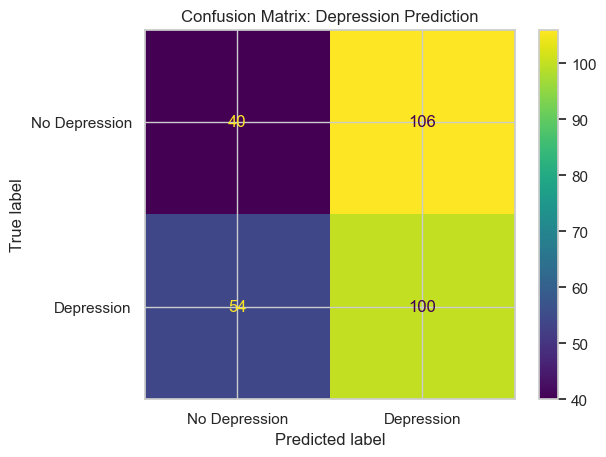

In [73]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate predictions on the test set
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=['No Depression', 'Depression']
    )
)

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Depression', 'Depression']
)

disp.plot()
plt.title("Confusion Matrix: Depression Prediction")
plt.show()


Accuracy: The model got fewer than half of the test predictions correct.



ROC-AUC: A score of 0.455 is below 0.5, the reference level for random ranking. This suggests the model's ability to rank positive cases above negative ones is poor.



Precision: Of the records predicted as Depression, 49% actually had a Yes label in the dataset.



F1-score: The Depression class scored 0.56, while No Depression scored 0.33, reflecting the model's uneven performance.



Macro F1-score: The average F1-score across both classes was 0.44.

### Conclusion: Evaluating The Depression Prediction Model

The Logistic Regression model achieved an accuracy of 46.7% and an ROC-AUC score of 0.455 on the test dataset. These results indicate that the model struggled to distinguish between records labeled Depression and No Depression.

Although the model identified approximately 64.9% of records labeled Depression, it correctly recognized only 27.4% of records labeled No Depression. Its performance was also below the accuracy of a simple baseline that predicts the majority class for every test record.

This experiment highlights an important lesson in data science: training a model successfully does not guarantee useful predictions. Data quality, feature selection, and careful evaluation all influence the reliability of the results. Repeated patient IDs also raised concerns about the dataset that should be considered when interpreting the findings.

The analysis is limited to the patterns present in this dataset. It does not establish the causes of depression or provide a reliable method for diagnosing individuals.

Ultimately, this project demonstrates both the potential and the limitations of machine learning when applied to human experiences. The numbers can help us investigate patterns, but they cannot tell the whole story of an individual's struggles, choices, or journey toward healing.

## Noah: A Man Who Finally Found Rest

OCD does not always announce itself in the same way. For Noah, the struggle began after a traumatic accident. For others, obsessive compulsive disorder may emerge through a different combination of biological, psychological, and environmental factors. Some people also have a family history of the condition.

But what happens when the people around you do not understand what you are experiencing?

Across some African communities, experiences involving unusual thoughts, voices, or behaviours may be interpreted through spiritual or traditional beliefs. A child struggling with mental health difficulties might be labelled possessed, called a water child, or accused of hearing the voice of the devil.

In some cases, attempts to help may involve flogging a child with a cane, immersing them in rivers, or taking them to traditional spiritual practitioners to drive away what is believed to be an evil spirit.

But what happens after the rituals? What happens when the thoughts return? What happens when the child is once again exposed to the very fears that torment them?

**What happens when the battle is still raging inside, even after everyone believes it has been defeated?**

This is why we must look beyond what the eyes can see.

OCD is more than a habit of keeping things tidy or repeating an action. It can involve relentless intrusive thoughts, distressing doubts, and compulsions that consume a person's time and peace of mind. It can exist alongside anxiety and depression, and the suffering can become overwhelming.

Sometimes, the thoughts may be frightening enough to make a person feel that life is no longer worth living. A person experiencing such thoughts deserves compassion, proper assessment, and support, not shame, punishment, or condemnation.

For Noah, the struggle had become exhausting.

He had attended several therapy sessions, yet the obsessive thoughts continued to cloud his mind. He was trying to find relief, but peace seemed to remain just beyond his reach.

Then, one day, he opened his Bible.

His eyes fell upon Matthew 11:28–30:

> “Come unto me, all ye that labour and are heavy laden, and I will give you rest.”

The words spoke to something deep within Noah. He had spent so much time fighting, questioning, worrying, and trying to quiet the storm in his mind. Here was an invitation not to carry every burden alone.

He kept reading.

As Noah grew deeper in his Christian faith, he reflected on the temptation of Jesus in the wilderness. In Matthew 4:8–10, Satan offered Jesus the kingdoms of the world in exchange for worship. Jesus rejected the temptation and commanded Satan to depart.

Noah found courage in this account. He began to understand his struggle through the language of his faith, turning to Scripture and prayer whenever the thoughts overwhelmed him. John 1:1, which declares that the Word was with God and the Word was God, became another passage he held close.

For Noah, the Bible was no longer merely a book to read. It became a source of hope, meaning, and reassurance in the middle of his struggle.

His journey was not about proving that every intrusive thought was a demon, nor did finding faith mean that he would never need professional support again. Rather, his faith gave him a way to face his suffering without believing that the suffering defined him.

And slowly, he began to see rest differently.

The biblical story of Noah tells of forty days and forty nights of rain, rising waters, and a world engulfed by a flood. It was a season of uncertainty, danger, and overwhelming turbulence. Yet the storm did not have the final word. Eventually, the waters receded, and the journey toward a new beginning became possible.

There is something deeply moving about that image.

Sometimes, a person's life can feel like a storm that refuses to end. The thoughts return. The questions return. The fear returns. And the person begins to wonder whether calm will ever come.

But Noah's story reminds us of the hope of rest after turbulence.

For the Noah in our story, that hope was found in Jesus. His faith did not erase the complexity of OCD, but it gave him a spiritual foundation on which to continue his journey toward peace.

Perhaps rest is not always the absence of a storm. Perhaps, sometimes, it begins with discovering that the storm does not have to define the whole of your life.

For Noah, the journey was not simply about silencing a voice. It was about finding hope amid the noise, learning to live with greater peace, and discovering that he did not have to face his burdens alone.

### A Little About the Author

My name is John. I am a deep thinker who questions everything and enjoys looking beyond the surface of things. I am curious about life, human behaviour, faith, and the deeper meanings behind our experiences.

Beyond writing and data science, I play the guitar, and trust me, I am good at it! 😂🎸

I love gospel music, especially deep worship that draws the heart closer to God. 

You can find my guitar videos on TikTok at **@jay_stringxxs**.

Feel free to explore my other projects, too. I enjoy asking questions, exploring ideas, and turning my thoughts into stories that inspire reflection and meaningful conversations.

Thanks for taking the time to read my work. ❤️